In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
pistack_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import violin
from edautils.plot import plot

os.chdir(pistack_dir)

In [68]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

plt.rcParams.update({
    # 'font.size': 12,
    # 'axes.titlesize': 12,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Lato'],
})

COLOR_MAPS = {
    "TOTAL": '#666666',
    "CT": '#b80058',
    "DISP": "#d95f02",
    "ELEC": '#5954d6',
    "POL": '#1b9e77',
    "PAULI": '#ebac23',
    'FRZ': '#a6cee3', 
    'ORB': '#27C488'
}

df = pd.read_csv('pi_stack_EDA.csv').iloc[:, 1:]
print('# Total pairs:', len(df))
print('# Repulsive pairs:', len(df.query('TOTAL > 0')))
print('# Attractive pairs:', len(df.query('TOTAL < 0')))

# CLS_DISP
df['DISP'] = np.where(np.isnan(df['DISP'].values), df['CLS_DISP'], df['DISP'])
processed_df = df.query('TOTAL < 0').drop(columns=['resnr_lig', 'restype_lig', 'reschain_lig', 'PREPARATION'])

for x, subdf in processed_df.groupby("type"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())


components = [
    ('TOTAL', 'TOTAL', 'Total'),
    ('MOD_PAULI', 'PAULI', 'Pauli'),
    ('CLS_ELEC', 'CLS_ELEC', 'Electrostatics'),
    ('DISP', 'DISP', 'Dispersion'),
    ('POLARIZATION', 'POL', 'Polarization'),
    ('CHARGE_TRANSFER', 'CT', 'Charge Transfer')
]

groups = ['P', 'T']

include_all = True
for c, label, pp in components:
    line = f'{pp}'
    if include_all:
        line += f'${np.mean(processed_df[c]):.2f}\\ ({np.median(processed_df[c]):.2f})$'
    for x in groups:
        data = processed_df.query(f'type == "{x}"')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    line += ' \\\\'
    print(line)

# Total pairs: 924
# Repulsive pairs: 10
# Attractive pairs: 914
P 492 -62.8768
T 422 -55.4049
Total$-18.11\ (-16.93)$ & $-21.96\ (-21.33)$ & $-13.62\ (-12.17)$ \\
Pauli$27.02\ (24.84)$ & $31.48\ (30.10)$ & $21.83\ (18.88)$ \\
Electrostatics$-11.04\ (-10.07)$ & $-11.97\ (-11.29)$ & $-9.95\ (-8.68)$ \\
Dispersion$-28.81\ (-27.55)$ & $-35.81\ (-34.96)$ & $-20.64\ (-19.66)$ \\
Polarization$-2.46\ (-2.16)$ & $-2.75\ (-2.55)$ & $-2.12\ (-1.67)$ \\
Charge Transfer$-2.83\ (-2.59)$ & $-2.90\ (-2.74)$ & $-2.74\ (-2.44)$ \\


# Parallel T-Shaped Comparison

# Violin + Bar Plots

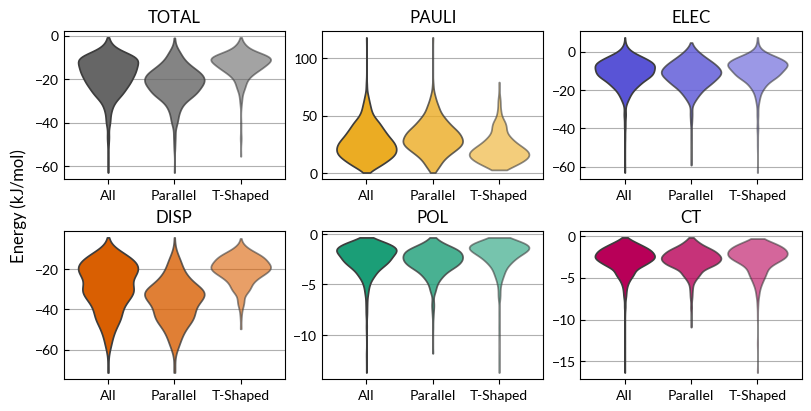

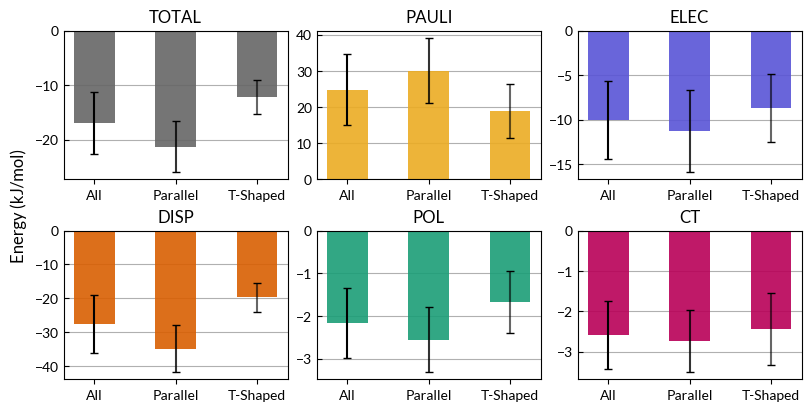

In [80]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'type'
groups = ['ALL', 'P', 'T']
labels = ['All', 'Parallel', 'T-Shaped']

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_TP.png')

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_TP.png')

# Pie Plot

In [81]:
def pie_TP(axes, group_name, groups, labels, processed_df):
    def compute_fraction(df):
        print(len(df))
        pol = np.mean(df['POLARIZATION'])
        ct = np.mean(df['CHARGE_TRANSFER'])
        elec = np.mean(df['CLS_ELEC'])
        pauli = np.mean(df['MOD_PAULI'])
        disp = np.mean(df['DISP'])

        orb = pol + ct
        stab = orb + elec + disp
        # print([elec/stab, disp/stab, pol/stab, ct/stab])
        # return [elec/stab, disp/stab, pol/stab, ct/stab]
        return [elec/stab, disp/stab, orb/stab]

    def find_label(x, data):
        # pcts = [data[0]/sum(data)*100, data[1]/sum(data)*100, data[2]/sum(data)*100, data[3]/sum(data)*100]
        pcts = [data[0]/sum(data)*100, data[1]/sum(data)*100, data[2]/sum(data)*100]
        if abs(pcts[0] - x) < 1e-5:
            return f'ELEC\n({x:.2f}%)'
        elif abs(pcts[1] - x) < 1e-5:
            return f'DISP\n({x:.2f}%)'
        # elif abs(pcts[2] - x) < 1e-5:
        #     return f'POL\n({x:.2f}%)'
        # elif abs(pcts[3] - x) < 1e-5:
        #     return f'CT\n({x:.2f}%)'
        elif abs(pcts[2] - x) < 1e-5:
            return f'ORB\n({x:.2f}%)'
        else:
            return f'{x:.2f}%'
        
    kwargs = dict(
        # colors=[COLOR_MAPS['ELEC'], COLOR_MAPS['DISP'], COLOR_MAPS['POL'], COLOR_MAPS['CT']], 
        colors=[COLOR_MAPS['ELEC'], COLOR_MAPS['DISP'], COLOR_MAPS['ORB']], 
        textprops=dict(fontsize=12),
        wedgeprops = {'linewidth': 3, 'clip_on': True},
        autopct=lambda p: find_label(p, data)
    )

    processed_df_all = processed_df.copy()
    if 'ALL' in groups:
        processed_df_all[group_name] = 'ALL' 
        processed_df_all = pd.concat([processed_df, processed_df_all])

    for i in range(len(groups)):
        data = compute_fraction(processed_df_all.query(f"{group_name} == '{groups[i]}'"))
        axes[i].pie(data, **kwargs)
        axes[i].set_title(labels[i], fontsize=14)
        axes[i].set_xlim(-1, 1)
        axes[i].set_ylim(-1.1, 1.1)
    
    return axes

914
492
422


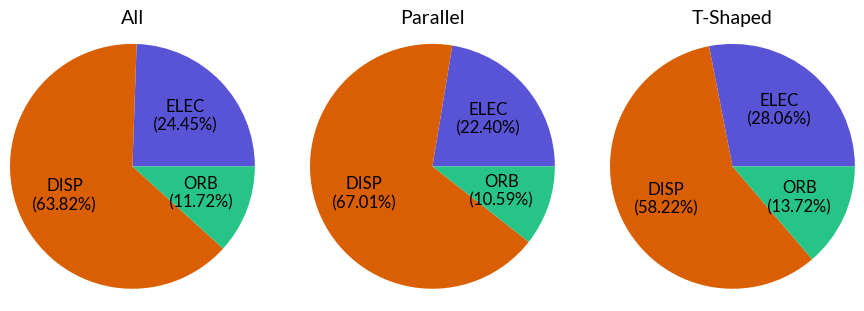

In [82]:
group_name = 'type'
groups = ['ALL', 'P', 'T']
labels = ['All', 'Parallel', 'T-Shaped']

fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie_TP(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie_TP.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_28904/3942391744.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_28904/3942391744.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


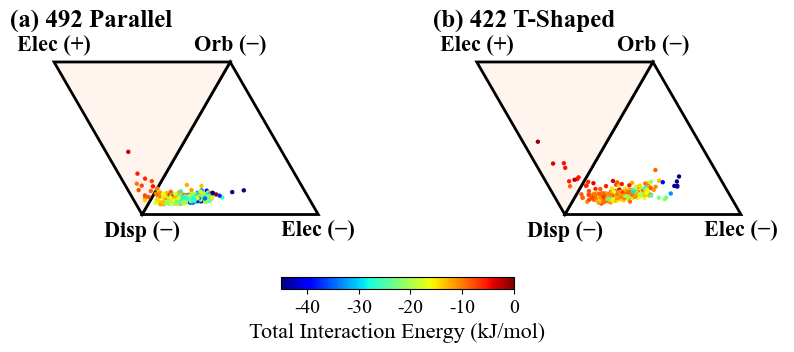

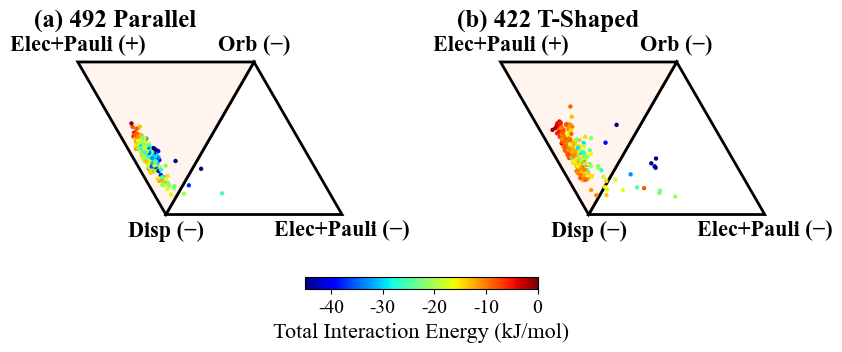

In [62]:
labels = ['Parallel', 'T-Shaped']

def split_type(df):
    dfList = []
    dfList.append(df.query('type == "P" & TOTAL < 0'))
    dfList.append(df.query('type == "T" & TOTAL < 0'))
    return dfList

dfs = split_type(df)
cmap_range = [-45, 0]
type0 = 'frz_orb_disp'
type1 = 'elec_orb_disp'
type2 = 'frz_pol_ct'


fig, axes = plt.subplots(1, 2, figsize=(10, 8))
sc = plot('ternary', (labels[0], 'a', type1), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type1), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary1_TP.png')


fig, axes = plt.subplots(1, 2, figsize=(10, 8))
sc = plot('ternary', (labels[0], 'a', type0), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type0), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary2_TP.png')


In [60]:
# items = [
#     # 'FROZEN', 
#     'CLS_ELEC', 
#     'MOD_PAULI', 
#     'DISP', 
#     # 'PAULI+DISP', 
#     'POLARIZATION', 
#     'CHARGE_TRANSFER', 
#     'TOTAL'
# ]
# dfs = split_type(df)

# print(f'len: list(map(len, dfs))')

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# plot('bar', (labels, items), dfs, axes[0])
# axes[0].set_title('Mean Energies')
# plot('bar', (labels, items), dfs, axes[1], median=True)
# axes[1].set_title('Median Energies')
# plt.savefig('Visualizations/bar_Energy_all_T-P.png')

# items = [
#     # 'FROZEN', 
#     'CLS_ELEC', 
#     # 'MOD_PAULI', 
#     'DISP', 
#     # 'PAULI+DISP', 
#     'POLARIZATION', 
#     'CHARGE_TRANSFER', 
#     'TOTAL'
# ]
# dfs = split_type(df)

# print(f'len: list(map(len, dfs))')

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# plot('bar', (labels, items), dfs, axes[0])
# axes[0].set_title('Mean Energies')
# plot('bar', (labels, items), dfs, axes[1], median=True)
# axes[1].set_title('Median Energies')
# plt.savefig('Visualizations/bar_Energy_pauli+disp_T-P.png')


# items_energy = [
#     # 'FROZEN', 
#     'CLS_ELEC', 
#     'MOD_PAULI', 
#     'DISP', 
#     # 'PAULI+DISP', 
#     'POLARIZATION', 
#     'CHARGE_TRANSFER', 
#     'TOTAL'
# ]


# items_ratio = [
#     # 'FROZEN', 
#     'CLS_ELEC', 
#     'MOD_PAULI', 
#     'DISP', 
#     # 'PAULI+DISP', 
#     'POLARIZATION', 
#     'CHARGE_TRANSFER', 
#     # 'TOTAL'
# ]


# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# plot('bar', (labels, items_energy), dfs, axes[0])
# axes[0].set_title('Mean Energies')
# plot('bar', (labels, items_ratio), dfs, axes[1], ratio2=True)
# axes[1].set_title('Mean Energies Ratio 2')
# plt.savefig('Visualizations/TP_bar.png')

# Heteroatom vs Pure Aromatic comparison

In [92]:
from edautils.fragment import find_rings_old
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

hetratom_prot = []
aromatic_prot = []

for index, row in processed_df.iterrows():
    if row['restype'] == 'TYR' or row['restype'] == 'PHE':
        aromatic_prot.append(index)
    else:
        hetratom_prot.append(index)

# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df['smiles1'])], subImgSize=(300, 300), molsPerRow=5)

dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
hetratom_lig = []
aromatic_lig = []

hetrato_atoms = []
aromatic_atoms = []

errs = []

for index, row in processed_df.iterrows():
    aromatic = True
    temp_atomlist = []
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    ring_list = find_rings_old(mol, find_hetero_rings=False, find_small_rings=False) # only aromatic rings, idx numbers in OpenBabel 1 lower than Plip

    lig_idx_list = row['lig_idx_list'].split()
    lig_idx_set = set([int(id) - 1 for id in lig_idx_list])
    ring_temp = [s for s in ring_list if lig_idx_set & s]
    
    if row['PDBID'] == '3b2q': # Plip ring missidentification
        ring_temp = [21, 22, 23, 24, 25, 27, 28, 29, 30]
    elif row['PDBID'] == '2cm8': # reassign to aromatic ring
        ring_temp = [8, 9, 10, 11, 12, 13] 

    try:
        for idx in ring_temp[0]:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
            if not symbol == 'C':
                aromatic = False

        if aromatic:
            aromatic_lig.append(index)
            aromatic_atoms.append((index, temp_atomlist)) # keep the list of atoms
        else:
            hetratom_lig.append(index)
            hetrato_atoms.append((index, temp_atomlist)) # keep the list of atoms
    except Exception as e:
        for idx in lig_idx_set:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
        errs.append([index, temp_atomlist])

errPDBID = [err[0] for err in errs]
print(errPDBID)

processed_df["group"] = pd.NA

for index, row in processed_df.iterrows():
    # if index in errPDBID:
    #     continue
    if index in hetratom_prot and index in hetratom_lig:
        processed_df.loc[index, "group"] = "Heterocyclic"
    elif index in aromatic_lig and index in aromatic_lig:
        processed_df.loc[index, "group"] = "Carbocyclic"
    else:
        processed_df.loc[index, "group"] = "Mixed"

print('\n')
for x, subdf in processed_df.groupby("group"):
    print(x, subdf.shape[0], subdf['TOTAL'].mean())

components = [
    ('TOTAL', 'TOTAL', 'Total'),
    ('MOD_PAULI', 'PAULI', 'Pauli'),
    ('CLS_ELEC', 'CLS_ELEC', 'Electrostatics'),
    ('DISP', 'DISP', 'Dispersion'),
    ('POLARIZATION', 'POL', 'Polarization'),
    ('CHARGE_TRANSFER', 'CT', 'Charge Transfer')
]

groups = ['Heterocyclic', 'Carbocyclic', 'Mixed']

include_all = False
for c, label, pp in components:
    line = f'{pp}'
    if include_all:
        line += f'${np.mean(processed_df[c]):.2f}\\ ({np.median(processed_df[c]):.2f})$'
    for x in groups:
        data = processed_df.query(f'group == "{x}"')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    line += ' \\\\'
    print(line)

[281, 321, 406, 543, 547, 600, 650, 791, 808]


Carbocyclic 409 -15.539523716381419
Heterocyclic 154 -20.857067532467532
Mixed 351 -19.895285754985757
Total & $-20.86\ (-20.35)$ & $-15.54\ (-14.35)$ & $-19.90\ (-19.04)$ \\
Pauli & $31.27\ (30.63)$ & $24.65\ (21.87)$ & $27.93\ (26.77)$ \\
Electrostatics & $-13.54\ (-12.34)$ & $-9.96\ (-8.67)$ & $-11.19\ (-10.69)$ \\
Dispersion & $-32.01\ (-30.54)$ & $-25.34\ (-23.41)$ & $-31.44\ (-31.20)$ \\
Polarization & $-3.41\ (-3.13)$ & $-2.16\ (-1.84)$ & $-2.40\ (-2.18)$ \\
Charge Transfer & $-3.17\ (-2.97)$ & $-2.74\ (-2.44)$ & $-2.79\ (-2.67)$ \\


# Violin + Bar Plots

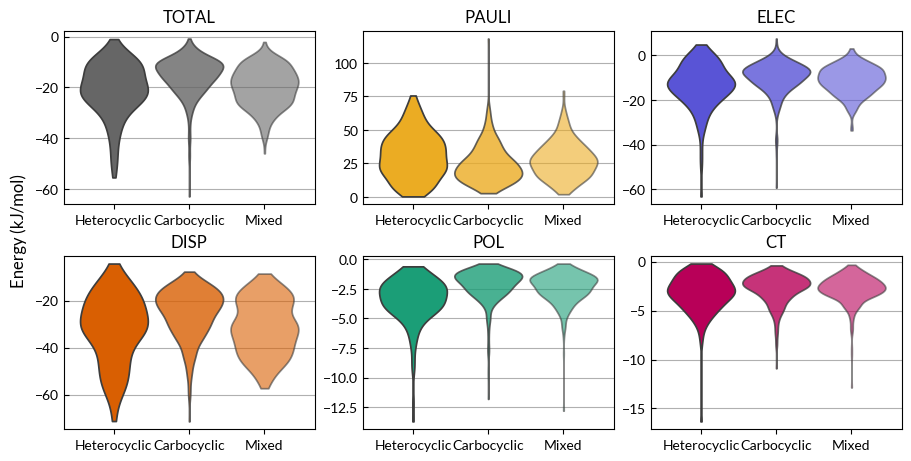

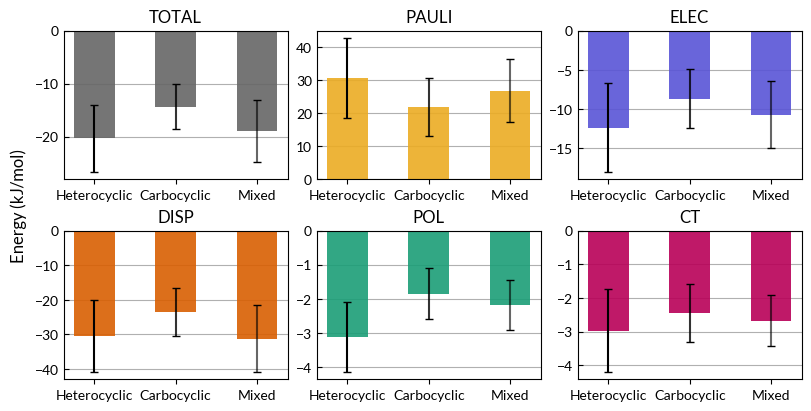

In [87]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'group'
groups = ['Heterocyclic', 'Carbocyclic', 'Mixed']
labels = ['Heterocyclic', 'Carbocyclic', 'Mixed']

fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_ring.png')

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_ring.png')

# Pie Plots

154
409
351


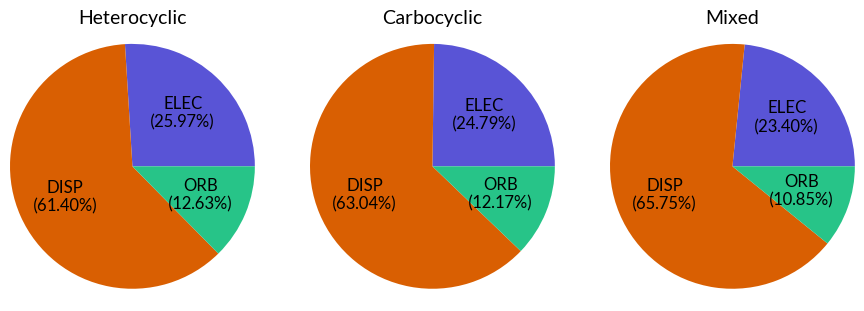

In [91]:
group_name = 'group'
groups = ['Heterocyclic', 'Carbocyclic', 'Mixed']
labels = ['Heterocyclic', 'Carbocyclic', 'Mixed']

fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie_TP(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie_ring.png')

In [96]:
labels = ['Heterocyclic', 'Carbocyclic', 'Mixed']

def split_hetr_aromatic(df, errPDBID):
    df0 = pd.DataFrame()
    df1 = pd.DataFrame()
    df2 = pd.DataFrame()

    for index, row in df.iterrows():
        # if index in errPDBID:
        #     continue
        if index in hetratom_prot and index in hetratom_lig:
            df0 = pd.concat([df0, row.to_frame().T])
        elif index in aromatic_lig and index in aromatic_lig:
            df1 = pd.concat([df1, row.to_frame().T])
        else:
            df2 = pd.concat([df2, row.to_frame().T])
    return [df0, df1, df2]

processed_dfs = split_hetr_aromatic(processed_df, errPDBID)

# Heteroatom vs Pure Aromatic Ternary

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_28904/3198668118.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


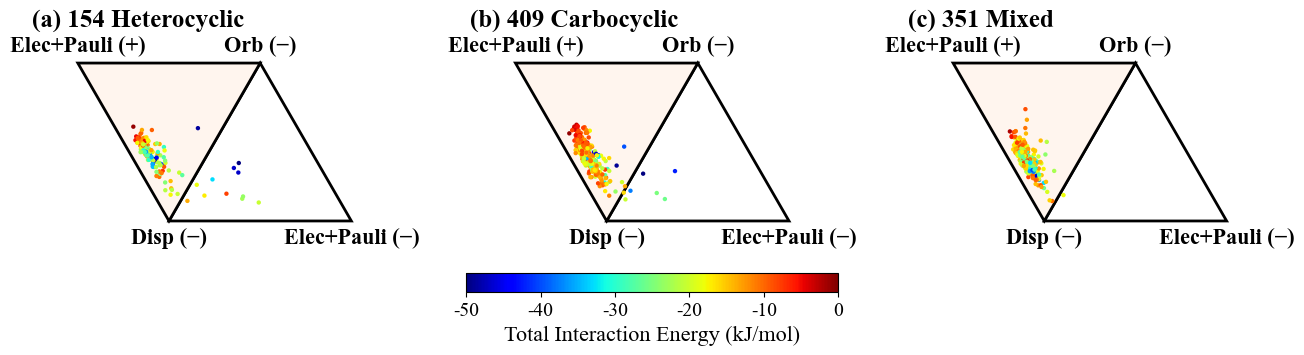

In [97]:
cmap_range = [-50, 0]
type = 'frz_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), processed_dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), processed_dfs[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), processed_dfs[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('Visualizations/ternary1_ring.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_28904/333471417.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


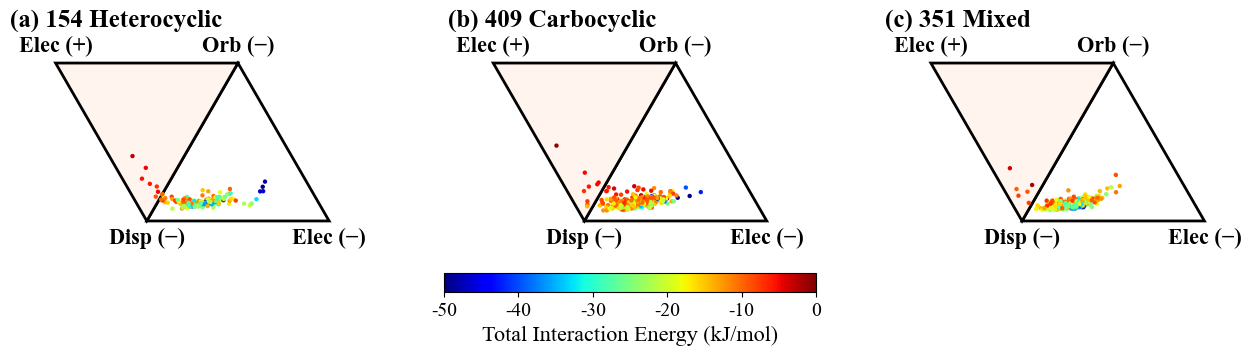

In [98]:
cmap_range = [-50, 0]
type = 'elec_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), processed_dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), processed_dfs[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), processed_dfs[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('Visualizations/ternary2_ring.png')